# rand_surface_views.py

*Generated from `rand_surface_views.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
rand_surface_views.py - regular vs random surface, side by side.

For W (reference (001)) and WC (reference basal (0001)):
  (a) the unrotated crystal with its regular top face and the plane random
      surface s cuts through it, (b) top view of the regular surface,
  (c) top view of random surface s;
same scale, the decks' impact square, colour = species, lighter = deeper.
Atoms are placed as in_rand_<MAT>.step1 places them (unrelaxed).

Outputs (--out): rand_regular_vs_random_W.png, _WC.png (1 x 3),
rand_regular_vs_random.png and _slide.png (2 x 3).

    python rand_surface_views.py [--s 7] [--out figs]
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'rand_surface_views.py'
NB_OUT = "nb_figs"
ARGS = ["--s", "7", "--out", NB_OUT]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import math
import os

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

import rand_geom as g

In [3]:
# ------------------------------------------------------------------ options
SURF_ID = 7                 # random surface shown (same s as the runs; see rand_angles_lammps.csv)
R_VIEW = 30.0               # hemisphere radius drawn in the top views (production R = 50 A)
DEPTH = 4.5                 # atoms within this depth below z_s are drawn (A)
BASAL_TOP = "C"             # "C" or "W": termination of the regular WC basal surface
BLOCK_HALF = {"W": 7.0, "WC": 7.5}     # half-width of the crystal block in panel (a) (A)
L_IMP = {"W": 4 * g.A_W, "WC": 11.7}   # impact square of the step-2 decks (A)
COL_PLANE, COL_IMP = "#3b78c4", "#ff8200"
SPECIES = {1: ("W", g.COL_W, 30), 2: ("C", g.COL_C, 14)}   # name, colour, marker size (top views)


def _shade(col, depth, dmax):
    """Species colour, blended toward white with depth (0 = top layer)."""
    c = np.array(to_rgb(col))
    f = np.clip(depth / dmax, 0, 1)[:, None] * 0.82
    return c[None, :] * (1 - f) + f


def reference_angles(mat):
    """(alpha, beta, gamma, ox, oy, oz) of the regular surface."""
    if mat == "W":
        return (0.0, 0.0, 0.0, 0.0, 0.0, 0.0)
    return (0.0, 0.0, 0.0, 0.0, 0.0, 0.5 if BASAL_TOP == "C" else 0.0)


def reference_name(mat):
    return "W(001)" if mat == "W" else "WC basal (0001), %s-terminated" % BASAL_TOP


def z_surface(p):
    """z_s as the decks define it: top atom within 8 A of the axis."""
    near = np.hypot(p[:, 0], p[:, 1]) <= 8.0
    return p[near, 2].max()

In [4]:
# ---------------------------------------------------------------- drawing
FS_TITLE = 11              # panel-title font size (the --slide figure uses 14)


def draw_topview(ax, mat, angles, title, R=R_VIEW):
    p, t, _ = g.hemisphere(mat, R, angles)
    zs = z_surface(p)
    depth = zs - p[:, 2]
    show = depth <= DEPTH
    order = np.argsort(-depth[show])            # deep first, top layer drawn last
    pp, tt, dd = p[show][order], t[show][order], depth[show][order]
    for typ, (name, col, size) in SPECIES.items():
        m = tt == typ
        if m.any():
            ax.scatter(pp[m, 0], pp[m, 1], s=size, c=_shade(col, dd[m], DEPTH), linewidths=0.3,
                       edgecolors="#00000055", zorder=2)
    L = L_IMP[mat]
    ax.add_patch(Rectangle((-L / 2, -L / 2), L, L, fill=False, ec=COL_IMP, lw=2.2, zorder=3))
    ax.add_patch(plt.Circle((0, 0), R, fill=False, ec="#999999", lw=0.8, ls="--", zorder=1))
    ax.set_xlim(-R - 1, R + 1); ax.set_ylim(-R - 1, R + 1)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(title, fontsize=FS_TITLE)
    top = dd < 1.0
    fC = float(np.mean(tt[top] == 2)) if mat == "WC" and top.any() else None
    return fC


def draw_block(ax, mat, angles, show_regular=True, label=None, half=None):
    """Unrotated crystal block + the plane surface s cuts through it (crystal frame)."""
    half = half or BLOCK_HALF[mat]
    al, be, ga, ox, oy, oz = angles
    n = g.normal(be, ga)
    p, t = g.lattice(mat, -half, half, (ox, oy, oz))
    s = p @ n                                    # signed distance from the cut (cut passes through 0)
    surf = (s <= 0) & (s > -2.2)                 # first ~2 A below the cut: the new surface layer
    above = s > 0                                # removed by the cut
    for typ, (name, col, size) in SPECIES.items():
        m = t == typ
        ax.scatter(*p[m & above].T, s=size * 0.5, c=col, alpha=0.10, linewidths=0, depthshade=False)
        ax.scatter(*p[m & ~above & ~surf].T, s=size * 0.6, c=col, alpha=0.35, linewidths=0, depthshade=False)
        ax.scatter(*p[m & surf].T, s=size * 1.4, c=col, alpha=1.0, edgecolors="k", linewidths=0.4,
                   depthshade=False)
    # cube edges
    c = np.array([-half, half])
    for x in c:
        for y in c:
            ax.plot([x, x], [y, y], c, color="k", lw=0.9)
            ax.plot([x, x], c, [y, y], color="k", lw=0.9)
            ax.plot(c, [x, x], [y, y], color="k", lw=0.9)
    if show_regular:                             # impact patch on the regular top face
        L = 0.45 * half
        sq = np.array([[-L, -L, half], [L, -L, half], [L, L, half], [-L, L, half]])
        ax.add_collection3d(Poly3DCollection([sq], facecolors=COL_IMP, alpha=0.55, edgecolors=COL_IMP))
    poly = g.plane_cube_polygon(n, 0.0, half)
    if len(poly):
        ax.add_collection3d(Poly3DCollection([poly], facecolors=COL_PLANE, alpha=0.22,
                                             edgecolors=COL_PLANE, linewidths=1.6, linestyles="--"))
        ax.quiver(0, 0, 0, *(n * half * 0.9), color=COL_PLANE, lw=2, arrow_length_ratio=0.15)
    # crystal axes
    axes = (("[100]", "[010]", "[001]") if mat == "W" else ("a [2$\\bar{1}\\bar{1}$0]", "[01$\\bar{1}$0]", "c [0001]"))
    for k, (lab, col) in enumerate(zip(axes, ("#d62728", "#2ca02c", "#1f1f9f"))):
        v = np.zeros(3); v[k] = 1.0
        o = np.array([-half, -half, -half])
        ax.quiver(*o, *(v * half * 0.7), color=col, lw=1.6, arrow_length_ratio=0.2)
        ax.text(*(o + v * half * 0.85), lab, color=col, fontsize=8)
    ax.set_xlim(-half, half); ax.set_ylim(-half, half); ax.set_zlim(-half, half)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=22, azim=-58)
    ax.set_axis_off()
    if label:
        ax.set_title(label, fontsize=FS_TITLE)
    return n


def material_row(axs, mat, s, fig=None):
    ang_r, src = g.get_angles(s)
    n = g.normal(ang_r[1], ang_r[2])
    lab, dev = g.plane_label(mat, n)
    approx = "" if dev < 0.5 else "≈"
    draw_block(axs[0], mat, ang_r,
               label="(a) unrotated %s crystal: regular top face\nand the plane cut by random surface %d" % (mat, s))
    note = "n = (%.2f, %.2f, %.2f), β = %.0f°, γ = %.0f°" % (n[0], n[1], n[2], ang_r[1], ang_r[2])
    fC_ref = draw_topview(axs[1], mat, reference_angles(mat), "(b) %s\nn = (0, 0, 1)" % reference_name(mat))
    fC = draw_topview(axs[2], mat, ang_r, "(c) random surface %d: %s%s\n%s" % (s, approx, lab, note))
    if fC is not None:
        for ax, f in ((axs[1], fC_ref), (axs[2], fC)):
            ax.text(0.5, -0.01, "top-layer C fraction %.2f" % f, transform=ax.transAxes, ha="center",
                    va="top", fontsize=FS_TITLE - 2, color="#444")
    return src


def legend_text(fig, src, y=0.01):
    fig.text(0.01, y, "Top views: unrelaxed atoms within %g Å of the top atom, lighter = deeper; W grey, C blue; "
             "orange square = He impact area of the step-2 decks; dashed circle R = %g Å (production 50 Å).  "
             "Angles: %s." % (DEPTH, R_VIEW, src), fontsize=8.5, color="#555555")


def main():
    global SURF_ID
    ap = argparse.ArgumentParser()
    ap.add_argument("--s", type=int, default=SURF_ID)
    ap.add_argument("--out", default="figs")
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)

    for mat in ("W", "WC"):
        fig = plt.figure(figsize=(15, 5.4))
        axs = [fig.add_subplot(1, 3, 1, projection="3d"), fig.add_subplot(1, 3, 2), fig.add_subplot(1, 3, 3)]
        src = material_row(axs, mat, a.s)
        legend_text(fig, src)
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        p = os.path.join(a.out, "rand_regular_vs_random_%s.png" % mat)
        fig.savefig(p, dpi=200); plt.close(fig); print("wrote", p)

    global FS_TITLE
    for slide in (False, True):
        FS_TITLE = 14 if slide else 11
        fig = plt.figure(figsize=(12, 8.6) if slide else (15, 10.2))
        for r, mat in enumerate(("W", "WC")):
            axs = [fig.add_subplot(2, 3, 3 * r + 1, projection="3d"), fig.add_subplot(2, 3, 3 * r + 2),
                   fig.add_subplot(2, 3, 3 * r + 3)]
            src = material_row(axs, mat, a.s)
        if not slide:
            legend_text(fig, src, y=0.005)
        fig.tight_layout(rect=(0, 0 if slide else 0.025, 1, 1))
        p = os.path.join(a.out, "rand_regular_vs_random%s.png" % ("_slide" if slide else ""))
        fig.savefig(p, dpi=200); plt.close(fig); print("wrote", p)

In [5]:
if __name__ == "__main__":
    main()

wrote nb_figs/rand_regular_vs_random_W.png


wrote nb_figs/rand_regular_vs_random_WC.png


wrote nb_figs/rand_regular_vs_random.png


wrote nb_figs/rand_regular_vs_random_slide.png


## Outputs

In [6]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


rand_regular_vs_random.png


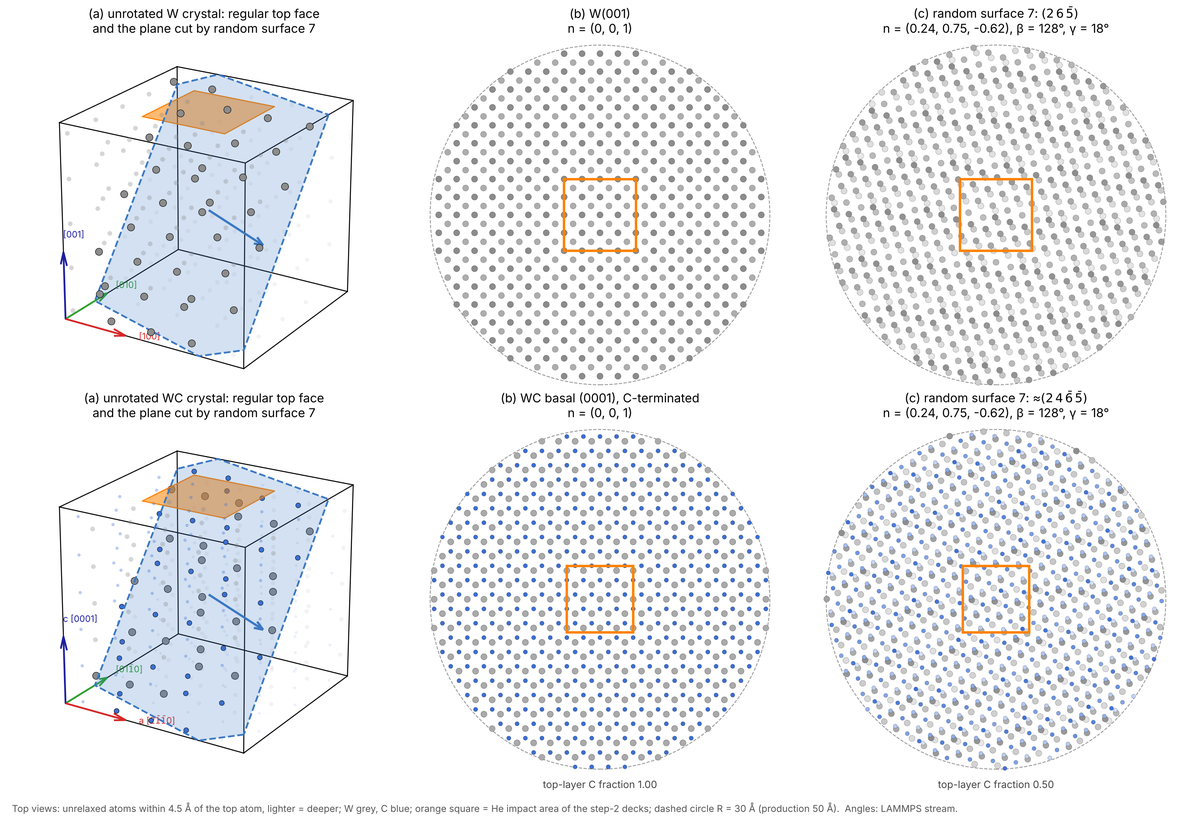

In [7]:
show(NB_OUT, ['rand_regular_vs_random.png'])